# Assignment 5: Autoencoders
Date: 

Report produced by:  
COMP 3705 Group 3

## Data Preprocessing

### Data Loading

In [12]:
import pandas as pd
import numpy as np
import math as m
from keras.models import Model, Sequential
from keras.layers import Input, Dense
import matplotlib.pyplot as plt
# Set TensorFlow deprication warnings to False
import tensorflow.python.util.deprecation as deprecation
deprecation._PRINT_DEPRECATION_WARNINGS = False

# Load the dataset
df = pd.read_csv("csvImages 10k x 784.csv")
df_clean = df.copy()
print("Data Shape:", df_clean.shape)

Data Shape: (9999, 784)


### Check Data Integrity

In [13]:
print("Number of Duplicate Rows:",df_clean.duplicated().sum())
print("Min value across all columns:",df_clean.min().min())
print("Max value across all columns:",df_clean.max().max())
print("Number of missing values in data:",df_clean.isna().sum().sum())

Number of Duplicate Rows: 1
Min value across all columns: 0
Max value across all columns: 255
Number of missing values in data: 0


As the data across all columns ranges between 0 and 255, we can determine that there are no unexpected RGB values.  
Additionally, since there are also no missing values anywhere in the data we can proceed with the dataset as-is.

In [14]:
df_clean = df_clean.drop_duplicates()
print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (9998, 784)


### Reshape for Visualizations

In [15]:
# Convert DataFrame to Numpy Array and Normalize Values
img_data = df_clean.values/255
img_data = img_data.reshape((-1,28,28))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 28, 28)
Shape of Each Row: (28, 28)


After checking the data, we converted the DataFrame into a NumPy array and normalized the pixel values by dividing them by 255. This changed the value range from 0–255 to  0–1. Normalization was done to helps the neural network train more effectively by ensuring no one pixel disproportionately influences the model.  
Next, we reshaped each image from 784 values into a 28 × 28 image. We did this because each row contains 784 points, each pertaining to a pixel in a 28x28 image. Reshaping the data allows us to display the images using Matplotlib before training the autoencoder.

### Pre-Encoding Visualizations

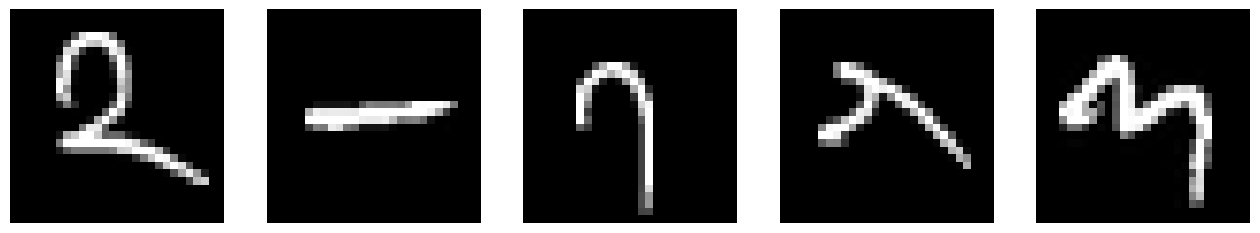

In [16]:
plt.figure(figsize=(16,10))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(img_data[i-1],cmap="gray")
    plt.axis("off")

### Reshape for Data Encoding

In [17]:
img_data = img_data.reshape((-1,28**2))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 784)
Shape of Each Row: (784,)


In [29]:
# Dummy Cell - Used for Run All Above - Remove Before Submission

## Model Selection

In [ ]:
activation_function = ["relu","sigmoid"]
activation_final = ["sigmoid","softmax"]
autoencoder = dict()
i = 0
# Define Input Layer
input_layer = Input(shape=(784,))
for act in activation_function:
    # Define Encoding Layers
    hidden_encoding1 = Dense(1024,activation=act)(input_layer)
    hidden_encoding2 = Dense(512,activation=act)(hidden_encoding1)
    hidden_encoding3 = Dense(256,activation=act)(hidden_encoding2)
    # Final Encoding Layer
    encoding_stage = Dense(64,activation=act)(hidden_encoding3)
    # Define Decoding Layers
    hidden_decoding1 = Dense(256,activation=act)(encoding_stage)
    hidden_decoding2 = Dense(512,activation=act)(hidden_decoding1)
    hidden_decoding3 = Dense(1024,activation=act)(hidden_decoding2)
    for act_fnl in activation_final:
        # Final Decoding Layer
        decoding_stage = Dense(784,activation=act_fnl)(hidden_decoding3)
        # Define Autoencoder Model
        autoencoder[i] = Model(input_layer,decoding_stage)
        i += 1

In [21]:
for i in len(autoencoder):
    autoencoder[i].compile(optimizer=,loss=)

SyntaxError: invalid syntax (3755763456.py, line 2)

### Final Selection

## Conclusion

### Image Visualizations

## Final Propositions


## Acknowledgement of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  

Load and Check Data - Sebastian Levy  
Normalize Data and Visualizations - Sebastian Levy  
Prepare Data for Encoding - Sebastian Levy  
Data Observations and Analysis - Sebastian Levy, Idongesit Orok, Miracle Okojie  


We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.